# Integrated decision tree

Preserve the supplied component unchanged in `components/decision_tree/original`. Its report uses different proxy labels, k=20 midpoint candidates and four folds; its scores are not copied into this comparison.

Retrain the supplied CV-selected tree configuration on the shared 32 features, frozen radius210m/K100 candidates, ordered alignment labels, remaining78 training trips and five saved trip folds. No new hyperparameter search or student-test selection is performed.

A median imputer is fitted inside each training fold and saved with the final model. Per-candidate positive probabilities are normalized within each point. Ties and scoring follow the same contract as the ranker. All valid held-out candidate rows, including candidate misses, receive OOF scores.

Fast fitting uses up to 250 complete GPS groups per trip (seed42), retaining all candidates within each sampled group. Validation and OOF cover every eligible point. Final fitting uses the same sample budget. This is not a full-row training run.

In [1]:
%run 06_shared_models.ipynb
from sklearn.tree import DecisionTreeClassifier, export_text, plot_tree
from sklearn.impute import SimpleImputer
from sklearn.pipeline import make_pipeline
from time import perf_counter
from datetime import datetime
from zoneinfo import ZoneInfo
import matplotlib.pyplot as plt
import joblib

output = Path("results/decision_tree_shared")
output.mkdir(parents=True, exist_ok=True)
feature_columns = shared_feature_columns
params = {"criterion": "entropy", "max_depth": 8, "min_samples_split": 100,
          "min_samples_leaf": 10, "max_features": 0.8, "class_weight": "balanced",
          "ccp_alpha": 0.00001, "random_state": seed}
config = {"params": params, "parameter_source": "components/decision_tree/original/DECISION_TREE_REPORT.md",
          "features": feature_columns, "feature_version": "direction_32", "training_exclusions": training_exclusions,
          "fold_file": contract["fold_file"], "candidate_settings": contract["candidate_settings"],
          "label_method": "shared ordered monotonic alignment; not original nearest-reference-arc proxy",
          "retuned": False, "training_groups_per_trip": 250, "validation": "all eligible held-out rows"}
(output / "config.json").write_text(json.dumps(config, indent=2) + "\n")
data, points = load_shared_training()
print("Shared candidate rows:", len(data), "| Valid GPS points:", len(points), flush=True)


def make_tree():
    return make_pipeline(SimpleImputer(strategy="median", keep_empty_features=True), DecisionTreeClassifier(**params))

sampled_groups = pd.concat([g.sample(n=min(250, len(g)), random_state=seed) for _, g in points.groupby("trip_id")])["group_id"]
sample_mask = data["group_id"].isin(sampled_groups)
sampled_groups.to_csv(output / "training_groups.csv", index=False)
print("Training sample:", int(sample_mask.sum()), "rows /", len(sampled_groups), "GPS groups", flush=True)

Shared candidate rows: 9202147 | Valid GPS points: 182635


Training sample: 1225774 rows / 19500 GPS groups


## Shared-fold OOF training

All preprocessing is fitted on the other four folds only. Do not mix the source component's independent candidate tables or four-fold results with this dataset. The final five-model comparison will use these shared scores.

In [2]:
probability_oof = np.full(len(data), np.nan, dtype=np.float64)
raw_oof = np.full(len(data), np.nan, dtype=np.float64)
records = []
def fit_fold(fold):
    training = data[(data["fold"] != fold) & sample_mask]
    validation = data[data["fold"] == fold]
    valid_points = points[points["fold"] == fold]
    assert set(training["trip_id"]).isdisjoint(validation["trip_id"])
    model = make_tree()
    start = perf_counter()
    model.fit(training[feature_columns], training["label"])
    fit_s = perf_counter() - start
    start = perf_counter()
    positive = int(np.flatnonzero(model.classes_ == 1)[0])
    raw = model.predict_proba(validation[feature_columns])[:, positive]
    probability = normalize_point_proba(raw, validation["group_id"])
    predict_s = perf_counter() - start
    record = {"fold": fold, **score_points(validation, probability, valid_points), "fit_s": fit_s, "predict_s": predict_s}
    return validation.index, probability, raw, record

from concurrent.futures import ThreadPoolExecutor, as_completed
with ThreadPoolExecutor(max_workers=3) as pool:
    for future in as_completed([pool.submit(fit_fold, fold) for fold in range(5)]):
        indices, probability, raw, record = future.result()
        probability_oof[indices], raw_oof[indices] = probability, raw
        records.append(record)
        pd.DataFrame(records).sort_values("fold").to_csv(output / "progress.csv", index=False)
        print("DT fold", record["fold"], "Top-1", record["top1"], flush=True)
records.sort(key=lambda r: r["fold"])

assert np.isfinite(probability_oof).all()
oof = data[["group_id", "segment_id", "fold"]].copy()
oof["score"], oof["raw_score"] = probability_oof, raw_oof
oof.to_csv(output / "oof_decision_tree.csv", index=False)
cv = pd.DataFrame(records)
cv.to_csv(output / "cv_metrics.csv", index=False)
pooled = score_points(data, probability_oof, points)
assert np.array_equal(np.sum([r["confusion_matrix"] for r in records], axis=0), pooled["confusion_matrix"])
(output / "pooled_metrics.json").write_text(json.dumps(pooled, indent=2) + "\n")
print("Shared DT pooled OOF:", pooled, flush=True)

DT fold 2 Top-1 0.9165728250712797


DT fold 0 Top-1 0.834715164482482


DT fold 1 Top-1 0.8467678147695405


DT fold 3 Top-1 0.9174680839097914


DT fold 4 Top-1 0.8785362181588596


Shared DT pooled OOF: {'top1': 0.8821693541763627, 'macro_f1': 0.9399794338131182, 'precision': 0.8821693541763627, 'recall': 0.8825124339957494, 'log_loss': 0.8930606317630014, 'candidate_coverage': 0.9996112464752102, 'points': 182635, 'candidate_misses': 71, 'confusion_matrix': [[8998063, 21520], [21449, 161115]]}


## Final fit and repeated student-test development evaluation

Use all remaining training trips. Test labels are attached only by the scoring helper, after prediction on the blank-label predictor table. These are repeated development results, not a new untouched evaluator test.
Use the fixed sample from all 78 eligible trips for the final estimator.

In [3]:
model = make_tree()
start = perf_counter()
model.fit(data.loc[sample_mask, feature_columns], data.loc[sample_mask, "label"])
final_fit_s = perf_counter() - start
bundle = {"model": model, "feature_columns": feature_columns, "model_type": "decision_tree",
          "feature_version": "direction_32", "params": params, "seed": seed,
          "excluded_trip_ids": training_exclusions, "training_groups_per_trip": 250}
joblib.dump(bundle, output / "model.joblib")
(output / "feature_columns.json").write_text(json.dumps(feature_columns, indent=2) + "\n")
test, test_points = load_shared_student_test()
start = perf_counter()
positive = int(np.flatnonzero(model.classes_ == 1)[0])
raw = model.predict_proba(test[feature_columns])[:, positive]
probability = normalize_point_proba(raw, test["group_id"])
predict_s = perf_counter() - start
predictions = test[["group_id", "segment_id"]].copy()
predictions["score"], predictions["raw_score"] = probability, raw
predictions.to_csv(output / "student_test_predictions.csv", index=False)
metrics = score_student_test(test, probability, test_points)
metrics["final_fit_s"], metrics["prediction_s"] = final_fit_s, predict_s
(output / "student_test_metrics.json").write_text(json.dumps(metrics, indent=2) + "\n")
reloaded = joblib.load(output / "model.joblib")
assert reloaded["feature_columns"] == feature_columns
np.testing.assert_allclose(reloaded["model"].predict_proba(test[feature_columns].iloc[:128]), model.predict_proba(test[feature_columns].iloc[:128]))
register_model("decision_tree", {"status": "trained", "kind": "sklearn_classifier",
    "model_path": str(output / "model.joblib"), "feature_columns_path": str(output / "feature_columns.json"),
    "oof_path": str(output / "oof_decision_tree.csv"), "student_test_scores_path": str(output / "student_test_predictions.csv"),
    "metrics_path": str(output / "student_test_metrics.json"), "hmm_config_path": None})
print("DT student-test:", metrics, flush=True)

DT student-test: {'top1': 0.8718162839248434, 'macro_f1': 0.934855851345118, 'precision': 0.8718162839248434, 'recall': 0.8718162839248434, 'log_loss': 0.8279657989809291, 'candidate_coverage': 1.0, 'points': 19160, 'candidate_misses': 0, 'confusion_matrix': [[1164522, 2456], [2456, 16704]], 'final_fit_s': 42.80611281099846, 'prediction_s': 0.43431590098771267}


## Model evidence and ledger

Plot actual fold metrics, the student-test confusion matrix, and the top tree levels. No artificial training-loss curve is created. The supplied report stays in the source archive; this notebook's measured results are the integrated component's evidence.

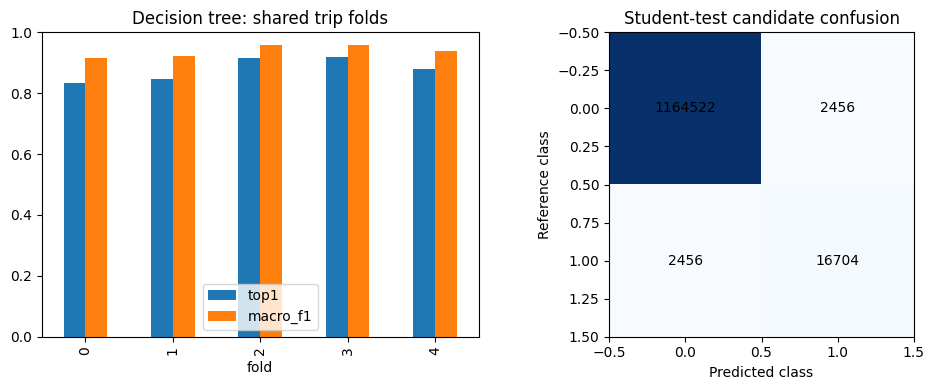

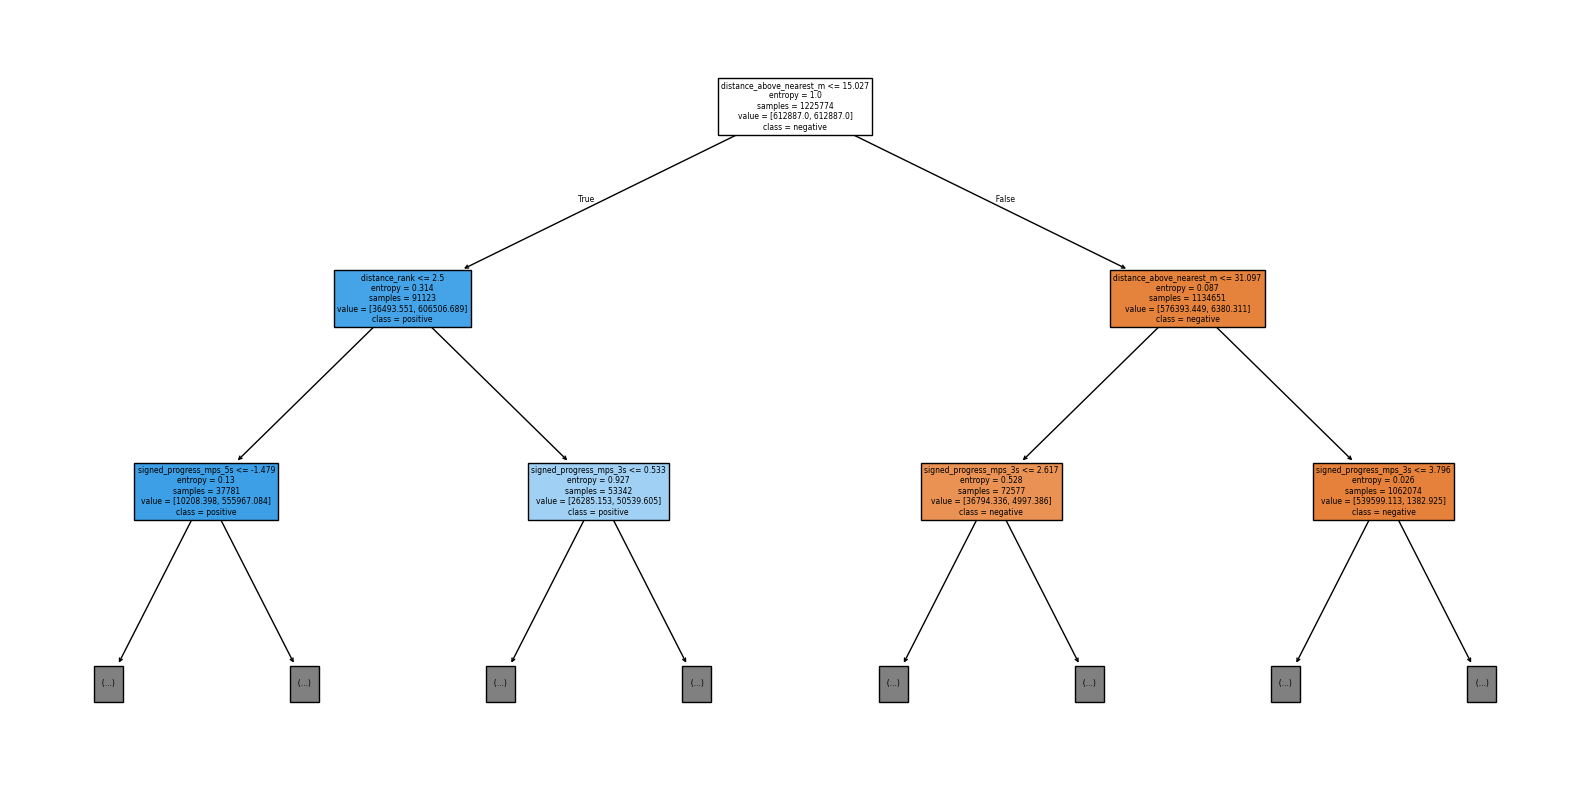

Integrated DT model, OOF, test predictions and plots saved.


In [4]:
fig, axes = plt.subplots(1, 2, figsize=(10, 4))
cv.plot(x="fold", y=["top1", "macro_f1"], kind="bar", ylim=(0, 1), ax=axes[0])
axes[0].set_title("Decision tree: shared trip folds")
axes[1].imshow(np.asarray(metrics["confusion_matrix"]), cmap="Blues")
axes[1].set_title("Student-test candidate confusion")
axes[1].set_xlabel("Predicted class"); axes[1].set_ylabel("Reference class")
for (i, j), value in np.ndenumerate(np.asarray(metrics["confusion_matrix"])):
    axes[1].text(j, i, str(value), ha="center", va="center")
plt.tight_layout(); plt.savefig(output / "metrics.png", dpi=150); plt.show()
fig, ax = plt.subplots(figsize=(16, 8))
plot_tree(model[-1], feature_names=feature_columns, class_names=["negative", "positive"], max_depth=2, filled=True, ax=ax)
plt.tight_layout(); plt.savefig(output / "tree_top_levels.png", dpi=150); plt.show()
(output / "tree_rules.txt").write_text(export_text(model[-1], feature_names=feature_columns, max_depth=3))
timestamp = datetime.now(ZoneInfo("Asia/Kolkata"))
row = {"run_id": "decision_tree_shared_" + timestamp.strftime("%Y%m%d_%H%M%S"), "timestamp": timestamp.isoformat(),
       "model": "decision_tree", "params": json.dumps(params), "seed": seed, "fold_scheme": contract["fold_scheme"],
       "feature_variant": "direction_32", "training_trips": 78, "excluded_trips": json.dumps(training_exclusions),
       "radius_m": contract["candidate_settings"]["radius_m"], "K": contract["candidate_settings"]["K"],
       "fit_s_mean": cv["fit_s"].mean(), "predict_s_mean": cv["predict_s"].mean(),
       "final_fit_s": final_fit_s, "final_predict_s": predict_s, "output_dir": str(output),
       "test_status": "repeated student-test development comparison"}
for metric in ["top1", "macro_f1", "precision", "recall", "log_loss", "candidate_coverage"]:
    row[f"cv_{metric}_mean"], row[f"cv_{metric}_std"] = cv[metric].mean(), cv[metric].std()
    row[f"pooled_{metric}"], row[f"test_{metric}"] = pooled[metric], metrics[metric]
ledger = Path("results/experiments.csv")
existing = pd.read_csv(ledger) if ledger.exists() else pd.DataFrame()
pd.concat([existing, pd.DataFrame([row])], ignore_index=True).to_csv(ledger, index=False)
print("Integrated DT model, OOF, test predictions and plots saved.")